In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.utils import timeseries_dataset_from_array
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, Dense

import warnings
warnings.filterwarnings("ignore")

In [24]:
url = "https://raw.githubusercontent.com/urgedata/pythondata/master/examples/climate-change-earth-surface-temperature-data/GlobalLandTemperaturesByMajorCity.csv"

df = pd.read_csv(url)

print("Dataset downloaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset downloaded successfully!
Shape: (239177, 7)


,dt,AverageTemperature,AverageTemperatureUncertainty,City,Country,Latitude,Longitude
0,1849-01-01,26.704,1.435,Abidjan,Côte D'Ivoire,5.63N,3.23W
1,1849-02-01,27.434,1.362,Abidjan,Côte D'Ivoire,5.63N,3.23W
2,1849-03-01,28.101,1.612,Abidjan,Côte D'Ivoire,5.63N,3.23W
3,1849-04-01,26.140,1.387,Abidjan,Côte D'Ivoire,5.63N,3.23W
4,1849-05-01,25.427,1.200,Abidjan,Côte D'Ivoire,5.63N,3.23W


In [25]:
print(df.info())

print("\nColumns:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Cities:", df["City"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 239177 entries, 0 to 239176
Data columns (total 7 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   dt                             239177 non-null  object 
 1   AverageTemperature             228175 non-null  float64
 2   AverageTemperatureUncertainty  228175 non-null  float64
 3   City                           239177 non-null  object 
 4   Country                        239177 non-null  object 
 5   Latitude                       239177 non-null  object 
 6   Longitude                      239177 non-null  object 
dtypes: float64(2), object(5)
memory usage: 12.8+ MB
None

Columns:
Index(['dt', 'AverageTemperature', 'AverageTemperatureUncertainty', 'City',
       'Country', 'Latitude', 'Longitude'],
      dtype='object')

Missing Values:
dt                                   0
AverageTemperature               11002
AverageTemperatureUncertainty    110

In [26]:
print(df[df["City"].str.contains("Delhi", case=False)]["City"].unique())

['Delhi' 'New Delhi']


In [27]:
city_df = df[
    (df["City"] == "Delhi") &
    (df["Country"] == "India")
].copy()

city_df = city_df.dropna(subset=["AverageTemperature"])

city_df["dt"] = pd.to_datetime(city_df["dt"])

city_df = city_df.sort_values("dt")

city_df.reset_index(drop=True, inplace=True)

print(city_df.shape)

city_df.head()

(2394, 7)


,dt,AverageTemperature,AverageTemperatureUncertainty,City,Country,Latitude,Longitude
0,1796-01-01,14.590,2.374,Delhi,India,28.13N,77.27E
1,1796-02-01,17.109,1.940,Delhi,India,28.13N,77.27E
2,1796-03-01,21.454,2.608,Delhi,India,28.13N,77.27E
3,1796-04-01,28.715,2.122,Delhi,India,28.13N,77.27E
4,1796-05-01,33.726,1.997,Delhi,India,28.13N,77.27E


In [28]:
temperature = city_df[["AverageTemperature"]]

print("Temperature Shape:", temperature.shape)

temperature.head()

Temperature Shape: (2394, 1)


,AverageTemperature
0,14.590
1,17.109
2,21.454
3,28.715
4,33.726


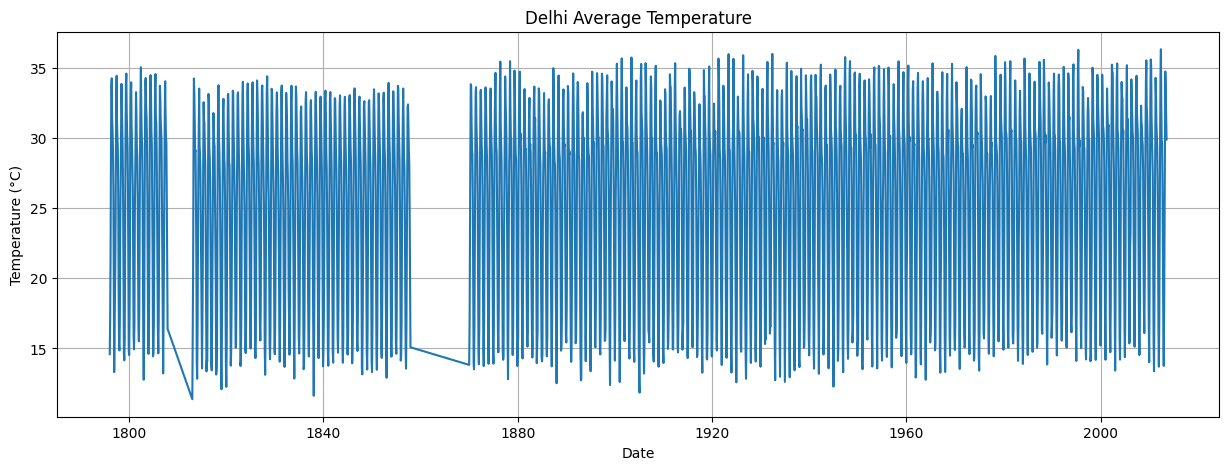

In [29]:
plt.figure(figsize=(15,5))

plt.plot(city_df["dt"], temperature)

plt.title("Delhi Average Temperature")

plt.xlabel("Date")

plt.ylabel("Temperature (°C)")

plt.grid(True)

plt.show()

In [30]:
scaler = MinMaxScaler()

train_size = int(len(temperature) * 0.80)

train_raw = temperature.iloc[:train_size]

test_raw = temperature.iloc[train_size:]

train = scaler.fit_transform(train_raw)

test = scaler.transform(test_raw)

print("Training Samples:", train.shape)

print("Testing Samples:", test.shape)

Training Samples: (1915, 1)
Testing Samples: (479, 1)


In [31]:
lookback = 30

batch_size = 32

train_dataset = timeseries_dataset_from_array(

    data=train[:-lookback],

    targets=train[lookback:],

    sequence_length=lookback,

    sequence_stride=1,

    shuffle=False,

    batch_size=batch_size

)

test_dataset = timeseries_dataset_from_array(

    data=test[:-lookback],

    targets=test[lookback:],

    sequence_length=lookback,

    sequence_stride=1,

    shuffle=False,

    batch_size=batch_size

)

print("Training batches:", len(train_dataset))

print("Testing batches:", len(test_dataset))

Training batches: 58
Testing batches: 14


In [32]:
for x, y in train_dataset.take(1):

    print("Input Shape:", x.shape)

    print("Output Shape:", y.shape)

Input Shape: (32, 30, 1)
Output Shape: (32, 1)


In [33]:
sample_sequences = [

    [1,2,3],

    [4,5],

    [6,7,8,9]

]

padded = pad_sequences(

    sample_sequences,

    maxlen=5,

    padding="pre"

)

print("Original Sequences:")

print(sample_sequences)

print("\nPadded Sequences:")

print(padded)

Original Sequences:
[[1, 2, 3], [4, 5], [6, 7, 8, 9]]

Padded Sequences:
[[0 0 1 2 3]
 [0 0 0 4 5]
 [0 6 7 8 9]]


In [34]:
simple_rnn = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(lookback,1)),

    tf.keras.layers.SimpleRNN(
        64,
        activation="tanh"
    ),

    tf.keras.layers.Dense(
        32,
        activation="relu"
    ),

    tf.keras.layers.Dense(1)

])

simple_rnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
simple_rnn.compile(

    optimizer="adam",

    loss="mse",

    metrics=["mae"]

)

In [36]:
callbacks = [

    tf.keras.callbacks.EarlyStopping(

        monitor="val_loss",

        patience=5,

        restore_best_weights=True

    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=3,

        verbose=1

    )

]

In [37]:
history_rnn = simple_rnn.fit(

    train_dataset,

    validation_data=test_dataset,

    epochs=10,

    callbacks=callbacks

)

Epoch 1/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0235 - mae: 0.0928 - val_loss: 0.0031 - val_mae: 0.0444 - learning_rate: 0.0010
Epoch 2/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0034 - mae: 0.0449 - val_loss: 0.0021 - val_mae: 0.0365 - learning_rate: 0.0010
Epoch 3/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0034 - mae: 0.0444 - val_loss: 0.0021 - val_mae: 0.0364 - learning_rate: 0.0010
Epoch 4/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0032 - mae: 0.0432 - val_loss: 0.0021 - val_mae: 0.0358 - learning_rate: 0.0010
Epoch 5/10
55/58 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0041 - mae: 0.0477
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0031 - mae: 0.0430 - val_loss: 0.0021 - val_mae: 0.0359 - learning_rate: 0.0010
Epoch 6/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0026 - mae: 0.0375 - val_loss: 0.0022 - val_mae: 0.0366 - learning_rate: 5.0000e-04
Epoch 

In [38]:
gru_model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(lookback,1)),

    tf.keras.layers.GRU(
        64,
        activation="tanh"
    ),

    tf.keras.layers.Dense(
        32,
        activation="relu"
    ),

    tf.keras.layers.Dense(1)

])

gru_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,977 (58.50 KB)

 Trainable params: 14,977 (58.50 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
gru_model.compile(

    optimizer="adam",

    loss="mse",

    metrics=["mae"]

)

In [40]:
history_gru = gru_model.fit(

    train_dataset,

    validation_data=test_dataset,

    epochs=10,

    callbacks=callbacks

)

Epoch 1/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.1129 - mae: 0.2639 - val_loss: 0.0382 - val_mae: 0.1646 - learning_rate: 0.0010
Epoch 2/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0189 - mae: 0.1105 - val_loss: 0.0082 - val_mae: 0.0759 - learning_rate: 0.0010
Epoch 3/10
53/58 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0082 - mae: 0.0729
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0078 - mae: 0.0726 - val_loss: 0.0080 - val_mae: 0.0733 - learning_rate: 0.0010
Epoch 4/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0066 - mae: 0.0669 - val_loss: 0.0073 - val_mae: 0.0699 - learning_rate: 5.0000e-04
Epoch 5/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0065 - mae: 0.0655 - val_loss: 0.0068 - val_mae: 0.0677 - learning_rate: 5.0000e-04


In [41]:
loss_gru, mae_gru = gru_model.evaluate(

    test_dataset,

    verbose=0

)

print("GRU Loss:", loss_gru)

print("GRU MAE:", mae_gru)

GRU Loss: 0.03816095367074013
GRU MAE: 0.1646062284708023


In [42]:
loss_gru, mae_gru = gru_model.evaluate(
    test_dataset,
    verbose=0
)

print("GRU Loss:", loss_gru)
print("GRU MAE:", mae_gru)

GRU Loss: 0.03816095367074013
GRU MAE: 0.1646062284708023


In [43]:
pred_rnn = simple_rnn.predict(test_dataset)

pred_gru = gru_model.predict(test_dataset)

actual = []

for x, y in test_dataset:
    actual.extend(y.numpy().flatten())

actual = np.array(actual).reshape(-1, 1)

print("SimpleRNN Predictions:", pred_rnn.shape)
print("GRU Predictions:", pred_gru.shape)
print("Actual Values:", actual.shape)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
SimpleRNN Predictions: (420, 1)
GRU Predictions: (420, 1)
Actual Values: (420, 1)


In [44]:
pred_rnn = scaler.inverse_transform(pred_rnn)

pred_gru = scaler.inverse_transform(pred_gru)

actual = scaler.inverse_transform(actual)

print("Predictions converted successfully!")

Predictions converted successfully!


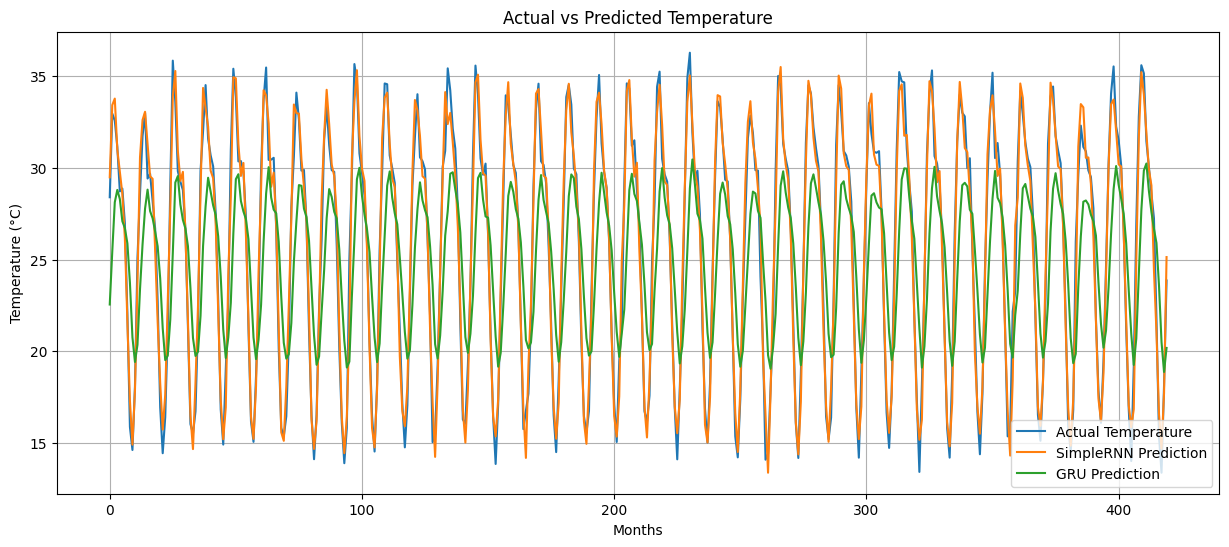

In [45]:
plt.figure(figsize=(15,6))

plt.plot(actual, label="Actual Temperature")

plt.plot(pred_rnn, label="SimpleRNN Prediction")

plt.plot(pred_gru, label="GRU Prediction")

plt.title("Actual vs Predicted Temperature")

plt.xlabel("Months")

plt.ylabel("Temperature (°C)")

plt.legend()

plt.grid(True)

plt.show()

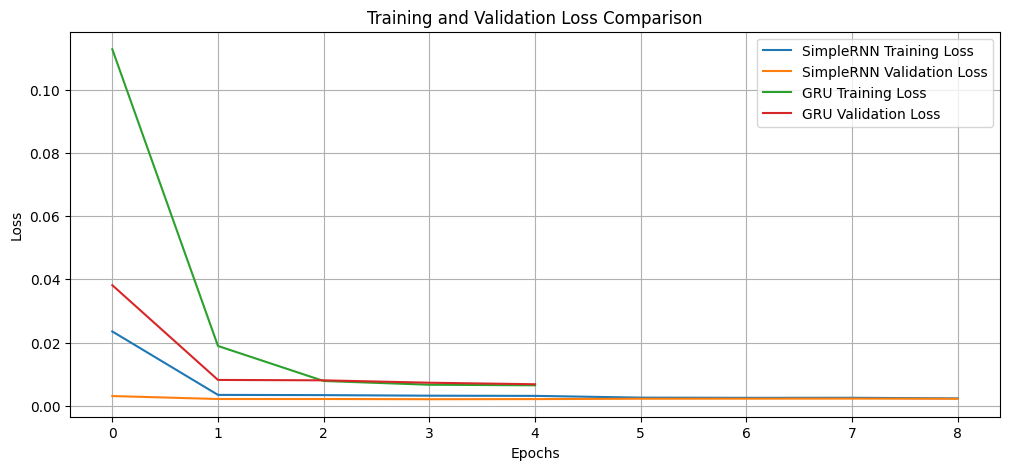

In [46]:
plt.figure(figsize=(12,5))

plt.plot(
    history_rnn.history["loss"],
    label="SimpleRNN Training Loss"
)

plt.plot(
    history_rnn.history["val_loss"],
    label="SimpleRNN Validation Loss"
)

plt.plot(
    history_gru.history["loss"],
    label="GRU Training Loss"
)

plt.plot(
    history_gru.history["val_loss"],
    label="GRU Validation Loss"
)

plt.title("Training and Validation Loss Comparison")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

In [47]:
loss_rnn, mae_rnn = simple_rnn.evaluate(
    test_dataset,
    verbose=0
)

loss_gru, mae_gru = gru_model.evaluate(
    test_dataset,
    verbose=0
)

print("SimpleRNN Loss:", loss_rnn)
print("SimpleRNN MAE:", mae_rnn)

print("GRU Loss:", loss_gru)
print("GRU MAE:", mae_gru)

SimpleRNN Loss: 0.0020580836571753025
SimpleRNN MAE: 0.035798199474811554
GRU Loss: 0.03816095367074013
GRU MAE: 0.1646062284708023


In [48]:
comparison = pd.DataFrame({

    "Model": ["SimpleRNN", "GRU"],

    "Loss": [loss_rnn, loss_gru],

    "MAE": [mae_rnn, mae_gru]

})

print(comparison)

       Model      Loss       MAE
0  SimpleRNN  0.002058  0.035798
1        GRU  0.038161  0.164606


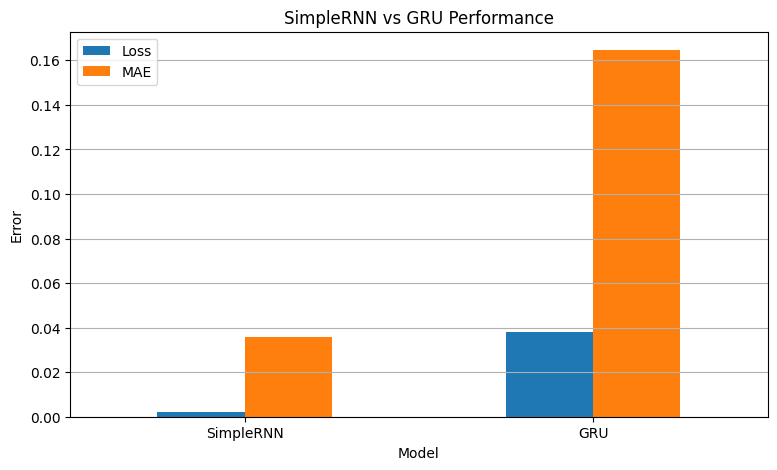

In [49]:
comparison.plot(
    x="Model",
    y=["Loss", "MAE"],
    kind="bar",
    figsize=(9,5)
)

plt.title("SimpleRNN vs GRU Performance")

plt.ylabel("Error")

plt.xlabel("Model")

plt.xticks(rotation=0)

plt.grid(axis="y")

plt.show()